# DEMO ISIC

## Imports and Loading

In [1]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

try:
    import cv2
except Exception:
    cv2 = None

try:
    import imagehash
except Exception:
    imagehash = None




In [2]:
PROJECT_DIR = Path("/Users/matteozabban/Desktop/CityU/EE4016/Project")

TRAIN_IMG_DIR = PROJECT_DIR / "ISIC_2019_Training_Input"
TEST_IMG_DIR  = PROJECT_DIR / "ISIC_2019_Test_Input"

TRAIN_GT_PATH   = PROJECT_DIR / "ISIC_2019_Training_GroundTruth.csv"
TRAIN_META_PATH = PROJECT_DIR / "ISIC_2019_Training_Metadata.csv"
TEST_META_PATH  = PROJECT_DIR / "ISIC_2019_Test_Metadata.csv"
TEST_GT_PATH    = PROJECT_DIR / "ISIC_2019_Test_GroundTruth.csv"   

train_gt = pd.read_csv(TRAIN_GT_PATH)
train_meta = pd.read_csv(TRAIN_META_PATH)
test_meta = pd.read_csv(TEST_META_PATH)

print("train_gt:", train_gt.shape)
print("train_meta:", train_meta.shape)
print("test_meta:", test_meta.shape)

print("train_gt cols:", train_gt.columns.tolist())
print("train_meta cols:", train_meta.columns.tolist())
print("test_meta cols:", test_meta.columns.tolist())

train_gt.head()

train_gt: (25331, 10)
train_meta: (25331, 5)
test_meta: (8238, 4)
train_gt cols: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
train_meta cols: ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']
test_meta cols: ['image', 'age_approx', 'anatom_site_general', 'sex']


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Data Cleaning and Preprocessing

In [3]:
def resolve_image_path(img_dir: Path, image_id: str):
    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        p = img_dir / f"{image_id}{ext}"
        if p.exists():
            return p
    matches = list(img_dir.rglob(f"{image_id}.*"))
    if matches:
        return matches[0]
    for p in img_dir.rglob("*"):
        if p.is_file() and p.stem.startswith(image_id):
            return p
    return None

def list_image_stems(img_dir: Path):
    exts = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}
    return {p.stem for p in img_dir.rglob("*") if p.is_file() and p.suffix in exts}

train_stems = list_image_stems(TRAIN_IMG_DIR)
test_stems = list_image_stems(TEST_IMG_DIR)

print("Train images on disk:", len(train_stems))
print("Test images on disk :", len(test_stems))

missing_train = set(train_gt["image"]) - train_stems
print("Missing train images referenced by GT:", len(missing_train))
print("Examples:", list(sorted(missing_train))[:10])

Train images on disk: 25331
Test images on disk : 8238
Missing train images referenced by GT: 0
Examples: []


In [4]:
ID_COL = "image"
ALL_CLASS_COLS = [c for c in train_gt.columns if c != ID_COL]

assert "UNK" in ALL_CLASS_COLS, "UNK not found in train_gt columns"

train_unk_sum = float(train_gt["UNK"].sum())
print("UNK sum TRAIN:", train_unk_sum)

CLASS_COLS = [c for c in ALL_CLASS_COLS if c != "UNK"]
print("Training classes (UNK removed):", CLASS_COLS)
print("num_classes:", len(CLASS_COLS))

idx_to_class = {i: c for i, c in enumerate(CLASS_COLS)}
class_to_idx = {c: i for i, c in idx_to_class.items()}

test_gt = None
if TEST_GT_PATH.exists():
    test_gt = pd.read_csv(TEST_GT_PATH)
    assert "UNK" in test_gt.columns, "UNK column not found in test_gt"

    n_before = len(test_gt)
    n_unk = int(test_gt["UNK"].sum())
    print("UNK sum TEST:", float(n_unk))

    test_gt = test_gt.loc[test_gt["UNK"] == 0].reset_index(drop=True)
    print(f"Dropped UNK rows from TEST GT: {n_unk}/{n_before} removed. Remaining: {len(test_gt)}")
else:
    print("TEST_GT_PATH not found -> skipping test_gt filtering.")

UNK sum TRAIN: 0.0
Training classes (UNK removed): ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
num_classes: 8
UNK sum TEST: 2047.0
Dropped UNK rows from TEST GT: 2047/8238 removed. Remaining: 6191


In [5]:
train = train_gt.copy()
train["label_idx"] = train[CLASS_COLS].values.argmax(axis=1)
train["label_name"] = train["label_idx"].map(idx_to_class)

train = train.merge(train_meta, on="image", how="left")
print("train merged shape:", train.shape)

train.head()

train merged shape: (25331, 16)


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK,label_idx,label_name,age_approx,anatom_site_general,lesion_id,sex
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,55.0,anterior torso,NaN,female
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,30.0,anterior torso,NaN,female
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,MEL,60.0,upper extremity,NaN,female
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,30.0,upper extremity,NaN,male
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,MEL,80.0,posterior torso,NaN,male


## Split-Aware

In [6]:
df = train.copy()

df["lesion_group"] = df["lesion_id"].astype("string")
df["lesion_group"] = df["lesion_group"].fillna("IMG_" + df["image"].astype("string"))

X = df[["image"]].values  # dummy
y = df["label_idx"].values
groups = df["lesion_group"].values

SEED = 42
N_SPLITS = 5
VAL_FOLD = 0  

sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
splits = list(sgkf.split(X, y, groups=groups))

train_idx, val_idx = splits[VAL_FOLD]
train_split = df.iloc[train_idx].reset_index(drop=True)
val_split   = df.iloc[val_idx].reset_index(drop=True)

print("train/val sizes:", len(train_split), len(val_split))

train_groups = set(train_split["lesion_group"])
val_groups = set(val_split["lesion_group"])
overlap = train_groups.intersection(val_groups)
print("Group overlap:", len(overlap))
if len(overlap) > 0:
    print("Example overlapping groups:", list(overlap)[:10])

def class_dist(df_part, name):
    counts = df_part["label_idx"].value_counts().sort_index()
    counts = counts.reindex(range(len(CLASS_COLS)), fill_value=0)
    pct = (counts / counts.sum()).values
    out = pd.DataFrame({
        "class": [idx_to_class[i] for i in range(len(CLASS_COLS))],
        f"{name}_count": counts.values,
        f"{name}_pct": np.round(pct, 4),
    })
    return out

dist_tr = class_dist(train_split, "train")
dist_va = class_dist(val_split, "val")

dist = dist_tr.merge(dist_va, on="class")
dist["abs_pct_diff"] = (dist["train_pct"] - dist["val_pct"]).abs()
print("\nClass balance train vs val:")
display(dist.sort_values("abs_pct_diff", ascending=False))

print("\nMean abs pct diff:", dist["abs_pct_diff"].mean())

def lesion_stats(df_part, name):
    non = df_part[df_part["lesion_id"].notna()].copy()
    if len(non) == 0:
        return pd.Series({"split": name, "non_missing_imgs": 0, "n_lesions": 0, "pct_multi_lesions": np.nan})
    grp = non.groupby("lesion_id").size()
    n_lesions = int(grp.shape[0])
    pct_multi = float((grp > 1).mean()) if n_lesions > 0 else np.nan
    return pd.Series({
        "split": name,
        "non_missing_imgs": int(len(non)),
        "n_lesions": n_lesions,
        "max_imgs_per_lesion": int(grp.max()),
        "pct_multi_lesions": pct_multi,
    })

stats = pd.DataFrame([lesion_stats(train_split, "train"), lesion_stats(val_split, "val")])
display(stats)

train_split.head(), val_split.head()

train/val sizes: 20327 5004
Group overlap: 0

Class balance train vs val:


,class,train_count,train_pct,val_count,val_pct,abs_pct_diff
2,BCC,2586,0.1272,737,0.1473,0.0201
0,MEL,3679,0.1810,843,0.1685,0.0125
1,NV,10376,0.5105,2499,0.4994,0.0111
6,VASC,177,0.0087,76,0.0152,0.0065
3,AK,713,0.0351,154,0.0308,0.0043
7,SCC,513,0.0252,115,0.0230,0.0022
4,BKL,2097,0.1032,527,0.1053,0.0021
5,DF,186,0.0092,53,0.0106,0.0014



Mean abs pct diff: 0.007524999999999988


,split,non_missing_imgs,n_lesions,max_imgs_per_lesion,pct_multi_lesions
0,train,18661,9478,31,0.428993
1,val,4586,2369,24,0.419164


(          image  MEL   NV  BCC   AK  BKL   DF  VASC  SCC  UNK  label_idx  \
 0  ISIC_0000000  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 1  ISIC_0000002  1.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          0   
 2  ISIC_0000003  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 3  ISIC_0000004  1.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          0   
 4  ISIC_0000006  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 
   label_name  age_approx anatom_site_general lesion_id     sex  \
 0         NV        55.0      anterior torso       NaN  female   
 1        MEL        60.0     upper extremity       NaN  female   
 2         NV        30.0     upper extremity       NaN    male   
 3        MEL        80.0     posterior torso       NaN    male   
 4         NV        25.0     posterior torso       NaN  female   
 
        lesion_group  
 0  IMG_ISIC_0000000  
 1  IMG_ISIC_0000002  
 2  IMG_ISIC_0000003  
 3  IMG_ISIC_0000004  
 4  IMG_ISIC_0000

,split,n,missing,missing_rate
0,train,20327,1666,0.081960
1,val,5004,418,0.083533


,class,train_rate,val_rate
5,NV,0.120085,0.121248
2,BKL,0.073915,0.081594
4,MEL,0.072030,0.085409


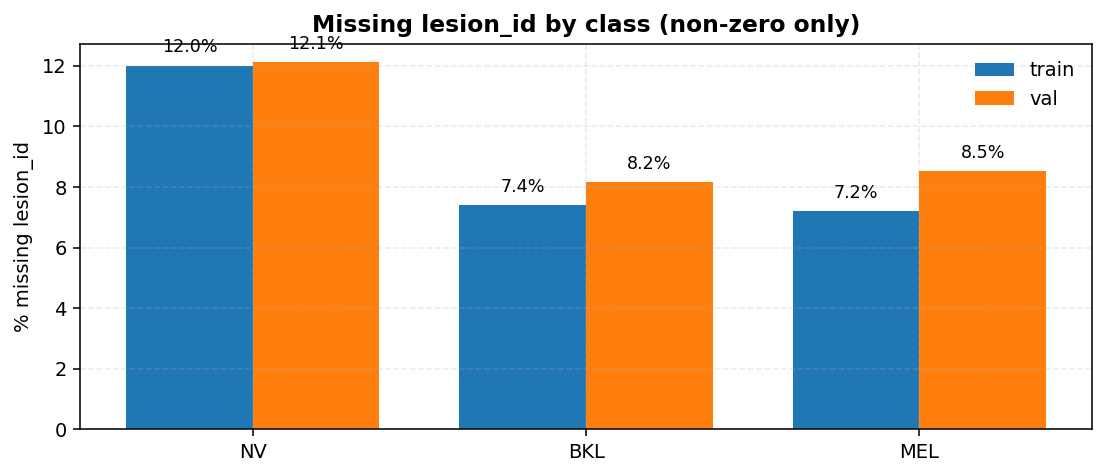

In [7]:
def missing_summary(df_part, name):
    n = len(df_part)
    miss = int(df_part["lesion_id"].isna().sum())
    return pd.Series({"split": name, "n": n, "missing": miss, "missing_rate": miss/n})

summary = pd.DataFrame([missing_summary(train_split, "train"),
                        missing_summary(val_split, "val")])
display(summary)

def missing_by_class(df_part, name):
    tmp = df_part.copy()
    tmp["missing"] = tmp["lesion_id"].isna().astype(int)
    g = tmp.groupby("label_idx")["missing"].agg(n="count", missing="sum").reset_index()
    g["class"] = g["label_idx"].map(lambda i: idx_to_class[int(i)])
    g[f"{name}_rate"] = g["missing"] / g["n"]
    return g[["class", f"{name}_rate"]]

mb = missing_by_class(train_split, "train").merge(missing_by_class(val_split, "val"), on="class", how="outer").fillna(0)
mb = mb[(mb["train_rate"] > 0) | (mb["val_rate"] > 0)].sort_values("train_rate", ascending=False)
display(mb)

x = np.arange(len(mb))
w = 0.38
plt.figure(figsize=(8,3.5), dpi=140)
b1 = plt.bar(x - w/2, mb["train_rate"]*100, width=w, label="train")
b2 = plt.bar(x + w/2, mb["val_rate"]*100, width=w, label="val")
plt.xticks(x, mb["class"], rotation=0)
plt.ylabel("% missing lesion_id")
plt.title("Missing lesion_id by class (non-zero only)", fontweight="bold")
plt.grid(True, alpha=0.25, linestyle="--")
plt.legend(frameon=False)
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x()+bar.get_width()/2, h+0.3, f"{h:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

## Live Demo Prediction

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMG_SIZE = 224

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

model = models.efficientnet_b0(pretrained=False)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, len(CLASS_COLS))

CHECKPOINT_PATH = PROJECT_DIR / "efficientnet_b0_cutmix_cosine_tta_demo.pth"   # <-- cambia questo path
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))

model = model.to(device)
model.eval()
print("Model loaded.")

Using device: mps


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Model loaded.


In [9]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(self._save_activation)
        self.backward_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

    def generate(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad()

        logits = self.model(x)

        if class_idx is None:
            class_idx = int(torch.argmax(logits, dim=1).item())

        score = logits[:, class_idx]
        score.backward()

        grads = self.gradients[0]   # [C, H, W]
        acts  = self.activations[0] # [C, H, W]

        weights = grads.mean(dim=(1, 2), keepdim=True)
        cam = (weights * acts).sum(dim=0)
        cam = torch.relu(cam)

        cam -= cam.min()
        cam /= (cam.max() + 1e-8)

        return cam.cpu().numpy(), class_idx

Loaded 8238 labeled test images.
Image ID:    ISIC_0034321
True label:  NV
Pred label:  NV
Confidence:  0.6150
Status:      CORRECT

Top-3 predictions:
  NV: 0.6150
  BCC: 0.2092
  MEL: 0.1394


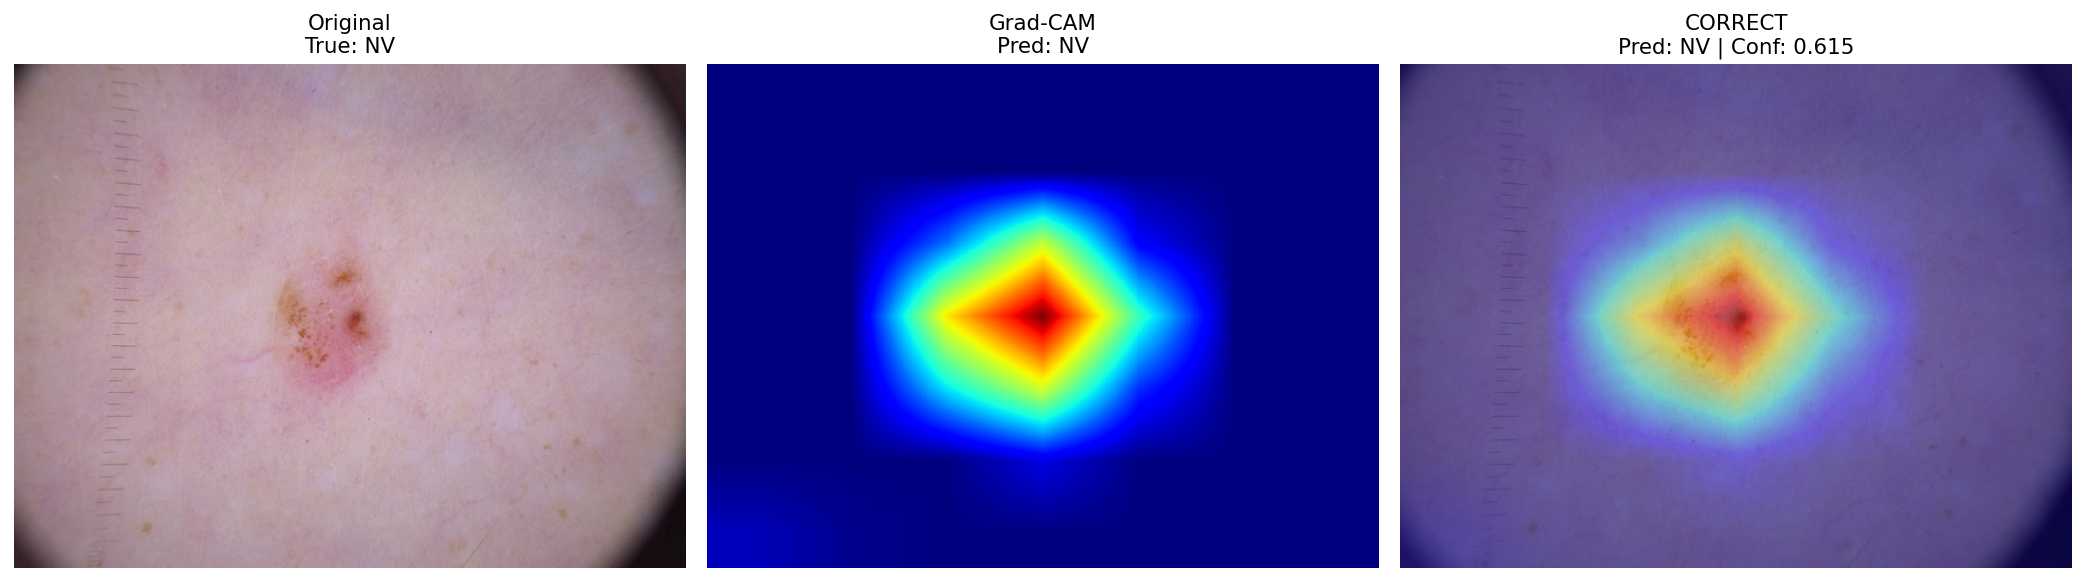

In [10]:

import tkinter as tk
from tkinter import filedialog
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# --------------------------------------------------
# Build test label lookup
# --------------------------------------------------
test_label_lookup = {}

if "test" in globals() and "image" in test.columns and "label_name" in test.columns:
    for _, r in test.iterrows():
        test_label_lookup[str(r["image"])] = str(r["label_name"])

elif "TEST_GT_PATH" in globals() and Path(TEST_GT_PATH).exists():
    test_gt = pd.read_csv(TEST_GT_PATH)

    ID_COL = "image"
    all_test_class_cols = [c for c in test_gt.columns if c != ID_COL]
    test_class_cols = [c for c in all_test_class_cols if c != "UNK"]

    test_idx_to_class = {i: c for i, c in enumerate(test_class_cols)}

    test_gt = test_gt.copy()
    test_gt["label_idx"] = test_gt[test_class_cols].values.argmax(axis=1)
    test_gt["label_name"] = test_gt["label_idx"].map(test_idx_to_class)

    if "UNK" in test_gt.columns:
        unk_mask = test_gt["UNK"] == 1
        test_gt.loc[unk_mask, "label_name"] = "UNK"

    for _, r in test_gt.iterrows():
        test_label_lookup[str(r["image"])] = str(r["label_name"])

else:
    raise ValueError("Could not build test label lookup. Make sure test labels are loaded.")

print(f"Loaded {len(test_label_lookup)} labeled test images.")

# --------------------------------------------------
# File picker from TEST_IMG_DIR with strict label check
# --------------------------------------------------
selected_path = None
true_label = None
image_id = None

while True:
    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    file_path = filedialog.askopenfilename(
        title="Select a TEST skin lesion image",
        initialdir=str(TEST_IMG_DIR),
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.JPG *.JPEG *.PNG"),
            ("All files", "*.*")
        ]
    )

    root.destroy()

    if not file_path:
        raise ValueError("No image selected.")

    file_path = Path(file_path)
    image_id = file_path.stem

    true_label = test_label_lookup.get(image_id, None)

    if true_label is None:
        print(f"Image '{image_id}' is not in the labeled test lookup. Please choose another image.\n")
        continue

    if str(true_label).upper() == "UNK":
        print(f"Image '{image_id}' has true label UNK. Please choose another image.\n")
        continue

    selected_path = file_path
    break

# --------------------------------------------------
# Load image and run prediction
# --------------------------------------------------
image_pil = Image.open(selected_path).convert("RGB")
x = val_transform(image_pil).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(x)
    probs = F.softmax(logits, dim=1)[0]
    pred_idx = int(torch.argmax(probs).item())
    pred_label = CLASS_COLS[pred_idx]
    confidence = float(probs[pred_idx].item())

top3_idx = np.argsort(probs.cpu().numpy())[::-1][:3]

# --------------------------------------------------
# Status
# --------------------------------------------------
status = "CORRECT" if true_label == pred_label else "WRONG"

# --------------------------------------------------
# Grad-CAM
# --------------------------------------------------
target_layer = model.features[-2]
gradcam_live = GradCAM(model, target_layer)

x_grad = val_transform(image_pil).unsqueeze(0).to(device)
cam, cam_pred_idx = gradcam_live.generate(x_grad)

cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize(
    image_pil.size, resample=Image.BILINEAR
)
cam_img = np.array(cam_img).astype(np.float32) / 255.0
original = np.array(image_pil).astype(np.float32) / 255.0

# --------------------------------------------------
# Print textual output
# --------------------------------------------------
print(f"Image ID:    {image_id}")
print(f"True label:  {true_label}")
print(f"Pred label:  {pred_label}")
print(f"Confidence:  {confidence:.4f}")
print(f"Status:      {status}")

print("\nTop-3 predictions:")
for idx in top3_idx:
    print(f"  {CLASS_COLS[idx]}: {probs[idx].item():.4f}")

# --------------------------------------------------
# Show image + Grad-CAM
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=140)

axes[0].imshow(original)
axes[0].set_title(f"Original\nTrue: {true_label}", fontsize=11)
axes[0].axis("off")

axes[1].imshow(cam_img, cmap="jet")
axes[1].set_title(f"Grad-CAM\nPred: {CLASS_COLS[cam_pred_idx]}", fontsize=11)
axes[1].axis("off")

axes[2].imshow(original)
axes[2].imshow(cam_img, cmap="jet", alpha=0.45)
axes[2].set_title(f"{status}\nPred: {pred_label} | Conf: {confidence:.3f}", fontsize=11)
axes[2].axis("off")

plt.tight_layout()
plt.show()

gradcam_live.remove_hooks()

## USER INPUT DEMO


Image ID / filename: voglia_zoom
True label: Unknown (external image)
Pred label: NV
Confidence: 0.9003

Top-3 predictions:
  NV: 0.9003
  MEL: 0.0860
  BKL: 0.0085


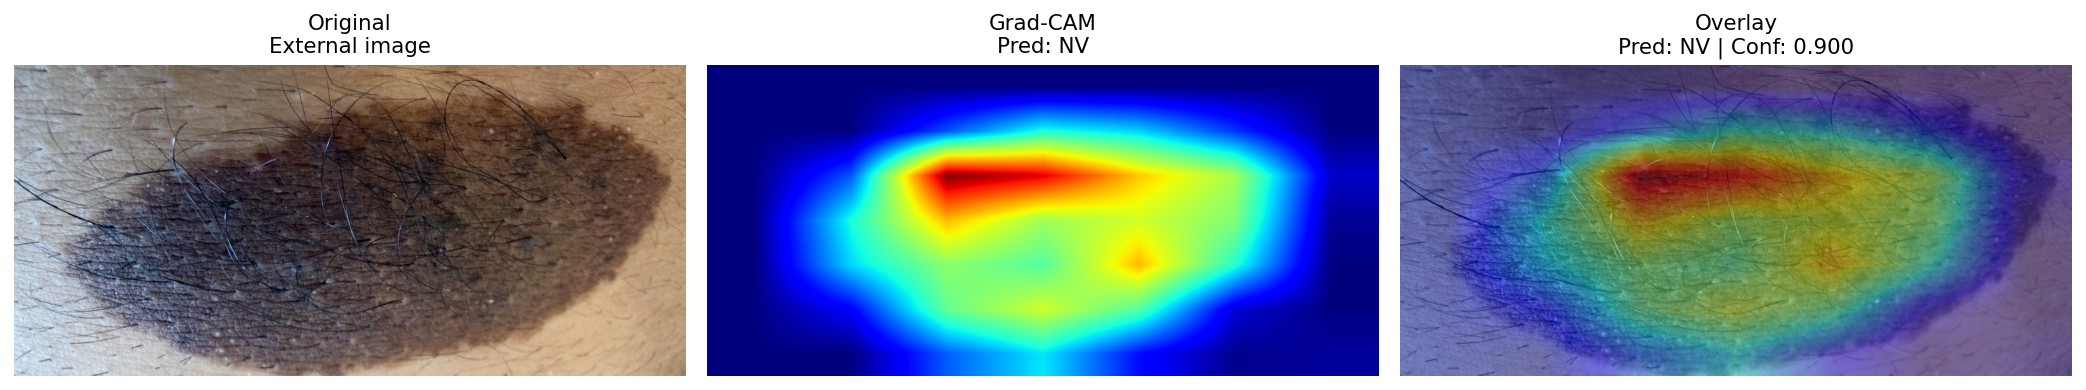

: 

In [ ]:
import tkinter as tk
from tkinter import filedialog
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

# --------------------------------------------------
# Open file picker for any local image
# --------------------------------------------------
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select any skin lesion image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.JPG *.JPEG *.PNG"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not file_path:
    raise ValueError("No image selected.")

file_path = Path(file_path)
image_id = file_path.stem

# --------------------------------------------------
# Load image and run prediction
# --------------------------------------------------
image_pil = Image.open(file_path).convert("RGB")
x = val_transform(image_pil).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(x)
    probs = F.softmax(logits, dim=1)[0]
    pred_idx = int(torch.argmax(probs).item())
    pred_label = CLASS_COLS[pred_idx]
    confidence = float(probs[pred_idx].item())

top3_idx = np.argsort(probs.cpu().numpy())[::-1][:3]

# --------------------------------------------------
# Grad-CAM
# --------------------------------------------------
target_layer = model.features[-1]
gradcam_live = GradCAM(model, target_layer)

x_grad = val_transform(image_pil).unsqueeze(0).to(device)
cam, cam_pred_idx = gradcam_live.generate(x_grad)

cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize(
    image_pil.size, resample=Image.BILINEAR
)
cam_img = np.array(cam_img).astype(np.float32) / 255.0
original = np.array(image_pil).astype(np.float32) / 255.0

# --------------------------------------------------
# Print textual output
# --------------------------------------------------
print(f"Image ID / filename: {image_id}")
print("True label: Unknown (external image)")
print(f"Pred label: {pred_label}")
print(f"Confidence: {confidence:.4f}")

print("\nTop-3 predictions:")
for idx in top3_idx:
    print(f"  {CLASS_COLS[idx]}: {probs[idx].item():.4f}")

# --------------------------------------------------
# Show image + Grad-CAM
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=140)

axes[0].imshow(original)
axes[0].set_title("Original\nExternal image", fontsize=11)
axes[0].axis("off")

axes[1].imshow(cam_img, cmap="jet")
axes[1].set_title(f"Grad-CAM\nPred: {CLASS_COLS[cam_pred_idx]}", fontsize=11)
axes[1].axis("off")

axes[2].imshow(original)
axes[2].imshow(cam_img, cmap="jet", alpha=0.45)
axes[2].set_title(f"Overlay\nPred: {pred_label} | Conf: {confidence:.3f}", fontsize=11)
axes[2].axis("off")

plt.tight_layout()
plt.show()

gradcam_live.remove_hooks()